# B1 · TF-IDF + linear SVM baseline

**EE6405 group project · EmotionShift · workstream #2 (Lixian)**

This notebook walks through the traditional-ML baseline step by step:

1. Load MELD and DailyDialog with the shared data rules from the proposal
2. Turn each utterance into TF-IDF features
3. Tune a linear classifier on the **dev** set only
4. Score once on **test**, overall and split by emotion shift
5. Look inside the model: which n-grams drive each emotion

B1 reads **one utterance at a time** (no dialogue context, no speaker), so it is the
reference point the context-aware models (#4 to #6) must beat. The full 5-seed run
with every output file is `scripts/train_b1.py`; this notebook reproduces its numbers
(LinearSVC is deterministic, so every seed gives the same model).

In [1]:
import sys, time, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from emotionshift.data.labels import EMOTIONS
from emotionshift.data.loaders import load, dailydialog_leakage
from emotionshift.models.tfidf import TfidfBaseline, TfidfConfig, _features, _classifier
from emotionshift.eval import metrics as M
from emotionshift.eval import plots as P

FIG = ROOT / "reports" / "b1" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)

## 1. Data

Two datasets, one table schema (`dataset, split, dialogue_id, turn, speaker, text, emotion, stratum, shift_type`).
Rules shared with the whole group (checked by `tests/test_data.py`):

* official splits; 7 shared labels (DailyDialog `happiness` = joy, `no_emotion` = neutral)
* a **shift** = emotion differs from the *same speaker's* previous utterance; a speaker's first turn is neither
* DailyDialog headline test set = **`test_dedup`** (dialogues that also appear verbatim in train removed)

In [2]:
meld, dd = load("meld"), load("dailydialog")
sizes = pd.DataFrame({
    "MELD": meld.groupby("split").size(),
    "DailyDialog": dd.groupby("split").size(),
}).reindex(["train", "dev", "test", "test_dedup"])
sizes

,MELD,DailyDialog
split,,
train,9989.0,87170
dev,1109.0,8069
test,2610.0,7740
test_dedup,NaN,7019


In [3]:
print("DailyDialog leakage:", dailydialog_leakage())
dist = pd.DataFrame({
    "MELD train": meld[meld.split == "train"].emotion.value_counts(normalize=True),
    "DailyDialog train": dd[dd.split == "train"].emotion.value_counts(normalize=True),
}).reindex(EMOTIONS) * 100
dist.round(1)

DailyDialog leakage: {'test_dialogues': 1000, 'unique_test_dialogues': 996, 'unique_test_verbatim_in_train': 105, 'test_sharing_first_two_turns': 182}


,MELD train,DailyDialog train
emotion,,
neutral,47.2,82.8
joy,17.4,12.8
surprise,12.1,1.8
anger,11.1,0.9
sadness,6.8,1.1
disgust,2.7,0.3
fear,2.7,0.2


Both datasets are dominated by *neutral* (MELD 47%, DailyDialog 83%), and fear / disgust
are around 1–3%. That imbalance is why we report macro-F1 next to the standard metrics
and try class-weighted training below.

An example MELD dialogue with the shift labels every model is scored on:

In [4]:
ex = meld[(meld.split == "test") & (meld.dialogue_id == 3)]
ex[["turn", "speaker", "text", "emotion", "stratum", "shift_type"]]

,turn,speaker,text,emotion,stratum,shift_type
1131,0,Steve,"Oh, okay, I get it.",neutral,first,NaN
1132,1,Ross,"No wait, look. Look! I'm sorry, it's just I've...",fear,first,NaN
1133,2,Steve,Howard's the,neutral,stable,NaN
1134,3,Ross,"Yes but too me he's just, man.",neutral,shift,offset
1135,4,Steve,"Okay, fine, whatever. Welcome to the building.",anger,shift,onset
1136,5,Ross,"Ugh, can you believe that guy!",disgust,shift,onset
1137,6,Phoebe,Yeah. I really like his glasses.,neutral,first,NaN


In [5]:
t = meld[meld.split == "test"]
print("MELD test strata:", t.stratum.value_counts().to_dict())
print("MELD test shift types:", t.shift_type.value_counts().to_dict())

MELD test strata: {'shift': 1003, 'stable': 861, 'first': 746}
MELD test shift types: {'onset': 355, 'offset': 340, 'surprise': 158, 'within_negative': 81, 'valence_flip': 69}


## 2. Method

**TF-IDF.** Each utterance $d$ becomes a sparse vector with one weight per n-gram $t$:

$$\mathrm{tfidf}(t,d) = \big(1+\log \mathrm{tf}(t,d)\big)\cdot \log\frac{1+N}{1+\mathrm{df}(t)} + 1,$$

then L2-normalised. Word 1–2-grams keep short cues ("oh my", "i love"); `!` and `?` are kept as
tokens because they matter for emotion. Optionally character 2–5-grams are added (robust to
spelling like "sooo" and "ugh").

**Linear SVM.** One-vs-rest: for each emotion $k$ learn $w_k$ minimising

$$\tfrac12\lVert w_k\rVert^2 + C\sum_i c_{y_i}\,\max\big(0,\,1 - y_{ik}\, w_k^\top x_i\big)^2,$$

and predict $\arg\max_k w_k^\top x$. $C$ trades margin against training errors; the class weight
$c_y = N / (7\,N_y)$ ("balanced") makes mistakes on rare emotions cost more.
Logistic regression (multinomial, L2) is tried as the alternative linear classifier.

In [6]:
vec = _features(TfidfConfig(features="word"))
tr = meld[meld.split == "train"]
X = vec.fit_transform(tr.text)
print("MELD train matrix:", X.shape, f"(density {X.nnz / np.prod(X.shape):.5f})")

row = X[tr.text.tolist().index("Oh my God!")] if "Oh my God!" in set(tr.text) else X[0]
names = vec.get_feature_names_out()
top = np.argsort(row.toarray().ravel())[::-1][:6]
print("Top TF-IDF weights for one utterance:", [(names[j], round(row[0, j], 3)) for j in top])

MELD train matrix: (9989, 11261) (density 0.00124)
Top TF-IDF weights for one utterance: [('god !', np.float64(0.479)), ('oh my', np.float64(0.447)), ('my god', np.float64(0.445)), ('god', np.float64(0.406)), ('my', np.float64(0.315)), ('oh', np.float64(0.272))]


## 3. Tuning on dev (MELD)

Grid: classifier × C × class weight × features, every point fitted on train and scored on **dev**.
Test is never used for choosing. (DailyDialog has 87K training utterances, so its grid ran in
`scripts/train_b1.py`; its dev results are loaded from `reports/b1/dailydialog/dev_grid.csv`.)

In [7]:
dev = meld[meld.split == "dev"]
rows = []
t0 = time.time()
for feats in ["word", "word+char"]:
    v = _features(TfidfConfig(features=feats)); Xtr, Xdev = v.fit_transform(tr.text), v.transform(dev.text)
    for clf in ["svm", "logreg"]:
        for C in [0.1, 0.3, 1.0, 3.0]:
            for cw in [None, "balanced"]:
                m = _classifier(TfidfConfig(classifier=clf, C=C, class_weight=cw)).fit(Xtr, tr.emotion)
                s = M.scores(dev.emotion, m.predict(Xdev))
                rows.append(dict(classifier=clf, C=C, class_weight=cw or "none", features=feats, **s))
grid = pd.DataFrame(rows).sort_values("weighted_f1", ascending=False)
print(f"{len(grid)} configurations in {time.time() - t0:.0f}s")
grid.head(8)[["classifier", "C", "class_weight", "features", "weighted_f1", "macro_f1"]]

32 configurations in 52s


,classifier,C,class_weight,features,weighted_f1,macro_f1
1,svm,0.1,balanced,word,0.549,0.399
17,svm,0.1,balanced,word+char,0.543,0.412
3,svm,0.3,balanced,word,0.540,0.392
19,svm,0.3,balanced,word+char,0.532,0.392
15,logreg,3.0,balanced,word,0.531,0.392
30,logreg,3.0,none,word+char,0.522,0.356
29,logreg,1.0,balanced,word+char,0.521,0.383
13,logreg,1.0,balanced,word,0.520,0.387


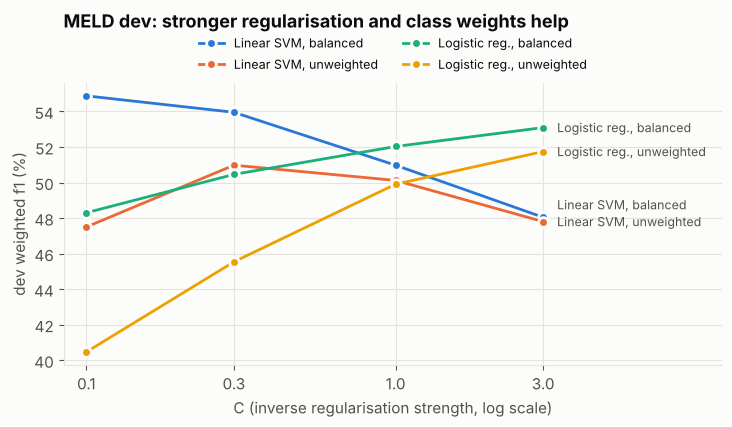

In [8]:
fig = P.tuning_chart(grid, "weighted_f1", "word", "MELD dev: stronger regularisation and class weights help")
fig.savefig(FIG / "meld_tuning.png", dpi=200); plt.show()

Reading the curve: the best MELD setting is a **linear SVM, C = 0.1, balanced class weights,
word n-grams**. Small C (strong regularisation) wins because MELD utterances are short and the
vocabulary is large relative to 10K training examples; balanced weights trade a little
majority-class accuracy for much better recall on rare emotions. Adding character n-grams
did not improve dev weighted-F1.

In [9]:
dd_grid = pd.read_csv(ROOT / "reports/b1/dailydialog/dev_grid.csv")
dd_grid.head(5)[["classifier", "C", "class_weight", "features", "micro_f1_no_neutral", "macro_f1"]]

,classifier,C,class_weight,features,micro_f1_no_neutral,macro_f1
0,svm,0.3,balanced,word,0.554,0.416
1,svm,0.3,balanced,word+char,0.548,0.408
2,svm,1.0,balanced,word,0.545,0.410
3,svm,1.0,none,word+char,0.544,0.406
4,svm,1.0,balanced,word+char,0.543,0.405


## 4. Final models, scored once on test

In [10]:
best = {
    "meld": dict(classifier="svm", C=0.1, class_weight="balanced", features="word"),
    "dailydialog": dict(classifier="svm", C=0.3, class_weight="balanced", features="word"),
}
assert grid.iloc[0][["classifier", "C", "class_weight", "features"]].tolist() == ["svm", 0.1, "balanced", "word"]

results, preds, models = [], {}, {}
for name, df, split in [("meld", meld, "test"), ("dailydialog", dd, "test_dedup"), ("dailydialog", dd, "test")]:
    if name not in models:
        train = df[df.split == "train"]
        models[name] = TfidfBaseline(TfidfConfig(**best[name], seed=0)).fit(train.text, train.emotion)
    t = df[df.split == split].copy()
    t["pred"] = models[name].predict(t.text)
    preds[(name, split)] = t
    s = M.scores(t.emotion, t.pred)
    head = M.HEADLINE[name]
    lo, hi = M.bootstrap_ci(t, head, n_boot=1000)
    results.append({"dataset": name, "split": split, "n": s["n"], "headline metric": head,
                    "headline": 100 * s[head], "95% CI": f"[{100*lo:.1f}, {100*hi:.1f}]",
                    "weighted_f1": 100 * s["weighted_f1"], "macro_f1": 100 * s["macro_f1"],
                    "micro_f1_no_neutral": 100 * s["micro_f1_no_neutral"]})
pd.DataFrame(results).round(2)

,dataset,split,n,headline metric,headline,95% CI,weighted_f1,macro_f1,micro_f1_no_neutral
0,meld,test,2610,weighted_f1,56.78,"[54.6, 58.9]",56.78,38.39,40.91
1,dailydialog,test_dedup,7019,micro_f1_no_neutral,53.03,"[49.9, 55.9]",83.88,46.16,53.03
2,dailydialog,test,7740,micro_f1_no_neutral,53.45,"[50.5, 56.1]",83.74,48.09,53.45


For context on MELD (weighted-F1): always-neutral 31.3, copying the speaker's previous
gold emotion 44.9, published context models DialogueGCN 58.1 and COSMIC 65.2. An
utterance-only bag of n-grams lands at **56.8**, close to DialogueGCN.

## 5. Where does B1 fail? Shift vs stable turns

In [11]:
mt = preds[("meld", "test")]
strat = M.stratified(mt)
strat.assign(weighted_f1=100 * strat.weighted_f1, macro_f1=100 * strat.macro_f1)[["group", "n", "weighted_f1", "macro_f1"]].round(1)

,group,n,weighted_f1,macro_f1
0,all,2610,56.8,38.4
1,stratum:first,746,62.2,40.8
2,stratum:stable,861,62.1,32.9
3,stratum:shift,1003,49.1,38.9
4,shift_type:onset,355,46.3,33.3
5,shift_type:offset,340,85.9,12.3
6,shift_type:surprise,158,51.6,28.7
7,shift_type:within_negative,81,32.1,16.5
8,shift_type:valence_flip,69,45.4,23.0


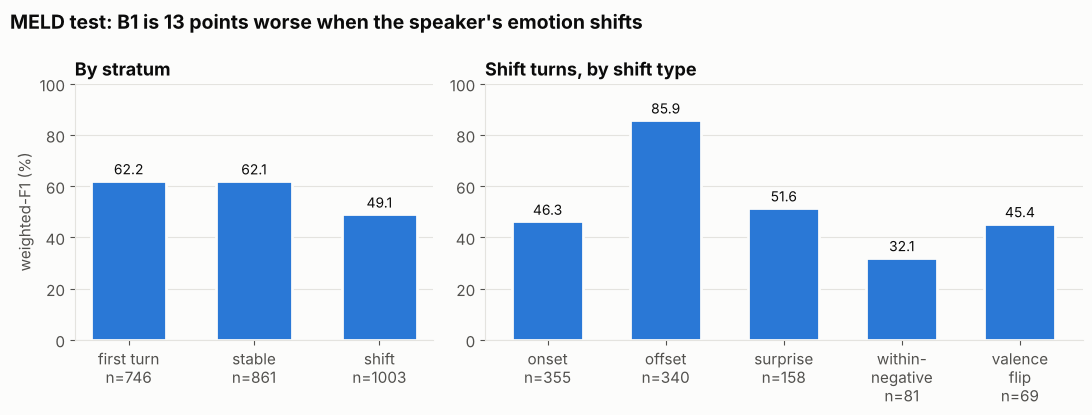

In [12]:
fig = P.strata_chart(strat, "MELD test: B1 is 13 points worse when the speaker's emotion shifts")
fig.savefig(FIG / "meld_strata.png", dpi=200); plt.show()

* **Shift turns 49.1 vs stable 62.1.** Even with no context at all, the turning points are where
  the model fails, which is exactly the gap the project studies (RQ1/RQ2).
* **Offsets look easy (85.9)** only because the gold label is neutral and B1 predicts neutral
  often; their macro-F1 is very low.
* **Within-negative shifts are hardest (32.1)**: anger → sadness or disgust → anger need more
  than surface words to tell apart.

In [13]:
print("Derived shift detection (predicted label vs speaker's previous predicted label):")
M.derived_shift_detection(mt)

Derived shift detection (predicted label vs speaker's previous predicted label):


{'n': 1864,
 'base_rate': 0.5380901287553648,
 'shift_f1': 0.6853080568720379,
 'predicted_shift_rate': 0.5938841201716738}

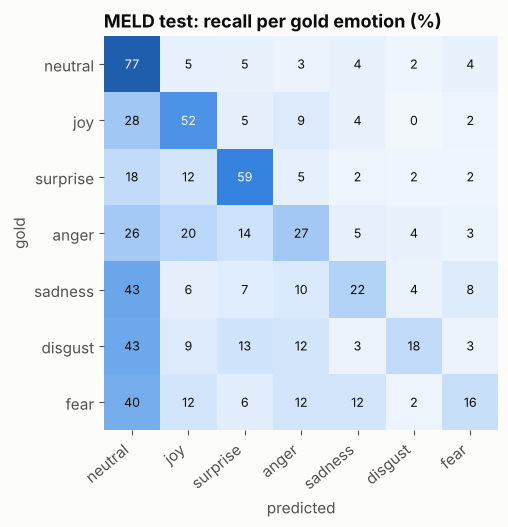

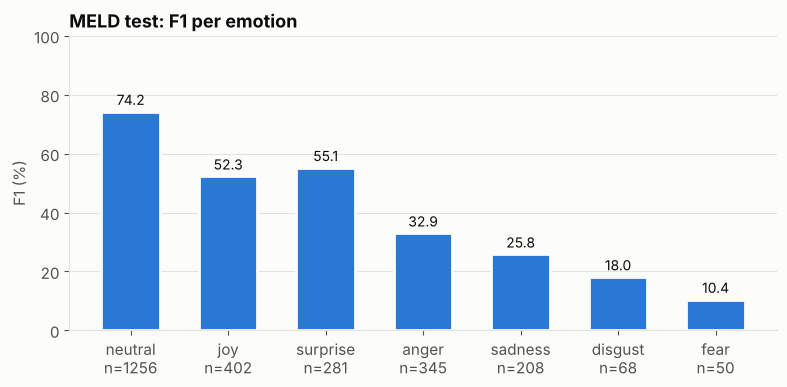

In [14]:
fig = P.confusion_chart(M.confusion(mt.emotion, mt.pred), "MELD test: recall per gold emotion (%)")
fig.savefig(FIG / "meld_confusion.png", dpi=200); plt.show()
fig = P.per_class_chart(M.per_class_f1(mt.emotion, mt.pred), "MELD test: F1 per emotion")
fig.savefig(FIG / "meld_per_class.png", dpi=200); plt.show()

Fear and disgust (about 2% of the data each) remain the weakest classes; most errors go to
*neutral*, which is also the most common error for the deep models in the literature.

## 6. Inside the model: top n-grams per emotion

In [15]:
top = models["meld"].top_features(10)
pd.DataFrame({e: top[e] for e in EMOTIONS})

,neutral,joy,surprise,anger,sadness,disgust,fear
0,okay,!,wow,!,sorry,ugh,scared
1,yeah,great,whoa,fine !,m sorry,disgusting,uh oh
2,hey,amazing,?,out !,so sorry,ew,please
3,hi,love,really ?,him !,hard,hate,no no
4,ok,i love,oh my,my,died,bug,oh no
5,hello,hi !,oh !,stop,old,pig,i i
6,no,pheebs !,my god,stupid,terry,freak,you you
7,sure,! i,? !,not,me,boat,oh god
8,need,great !,wow !,rachel !,never gonna,rocks,uh
9,right,right !,!,on !,can t,weird !,wait wait


The weights are readable: surprise ← *wow, whoa, really ?*; disgust ← *ugh, ew, disgusting*;
sadness ← *sorry*; fear ← *scared, oh no*; joy ← *!, great, love*. Short, lexically marked
emotions are what a bag of n-grams captures, and what it cannot see (sarcasm, tone, context)
is where the context-aware models should gain.

## 7. Try it

In [16]:
m = models["meld"]
lines = ["Oh my God! You got the job?!", "Yeah.", "I'm so sorry about your dad.",
         "Get out of my apartment!", "Ew, what is that smell?", "I'm scared, what if he finds out?"]
proba = m.predict_proba(lines)
pd.DataFrame({"utterance": lines, "prediction": m.predict(lines),
              "confidence": proba.max(axis=1).round(2)})

,utterance,prediction,confidence
0,Oh my God! You got the job?!,surprise,0.43
1,Yeah.,neutral,0.47
2,I'm so sorry about your dad.,sadness,0.39
3,Get out of my apartment!,anger,0.24
4,"Ew, what is that smell?",disgust,0.28
5,"I'm scared, what if he finds out?",fear,0.21


Note "Yeah." gets neutral regardless of tone: one-word turns are labelled from voice and context
in MELD, which a text-only, utterance-only model cannot see (the proposal's text-only limitation).

## 8. Efficiency (E9)

Parameters, training time, model size and the per-utterance CPU latency the demo will see
(one utterance per call; the proposal's demo budget is 300 ms per turn).

In [17]:
from emotionshift.eval import efficiency as E
rows = []
for name in ["meld", "dailydialog"]:
    df = meld if name == "meld" else dd
    train = df[df.split == "train"]
    t0 = time.perf_counter()
    mdl = TfidfBaseline(TfidfConfig(**best[name], seed=0)).fit(train.text, train.emotion)
    fit_s = time.perf_counter() - t0
    path = ROOT / "models" / f"_nb_b1_{name}.joblib"; path.parent.mkdir(exist_ok=True); mdl.save(path)
    clf = mdl.pipe.named_steps["clf"]
    lat = E.latency_ms(mdl.predict, df[df.split == "test"].text)
    rows.append({"dataset": name, "features": clf.coef_.shape[1], "parameters": clf.coef_.size + clf.intercept_.size,
                 "model file (MB)": round(E.file_size_mb(path), 2), "train (s)": round(fit_s, 1),
                 "latency median (ms)": round(lat["median_ms"], 2), "latency p95 (ms)": round(lat["p95_ms"], 2)})
    path.unlink()
print(E.machine())
pd.DataFrame(rows)

{'platform': 'Linux-6.18.44-fc-v153-x86_64-with-glibc2.39', 'processor': 'x86_64', 'cpu_count': 2, 'python': '3.13.17'}


,dataset,features,parameters,model file (MB),train (s),latency median (ms),latency p95 (ms)
0,meld,11261,78834,0.88,0.3,0.50,0.75
1,dailydialog,98289,688030,7.90,7.9,0.49,0.79


B1 is tiny: under 80K parameters on MELD, a model file under 1 MB, seconds to train, and
well under a millisecond per utterance, so it costs the demo essentially nothing.

## Takeaways

* B1 reaches **56.8 weighted-F1 on MELD** and **53.0 micro-F1 (excl. neutral) on de-duplicated
  DailyDialog**, a strong floor for the transformer models.
* Tuning on dev chose a **linear SVM with balanced class weights**; strong regularisation suits
  short utterances.
* B1 is **13 points worse on shift turns than on stable turns** on MELD, the gap the
  context and ShiftAware models are designed to close.
* It is **cheap**: under 1 MB, seconds to train, under 1 ms per utterance on CPU.

Sources: Poria et al. (2019) MELD; Li et al. (2017) DailyDialog; Joachims (1998) text
categorisation with SVMs; scikit-learn (Pedregosa et al., 2011).